# Bases do cotidiano: soda, cal e antiácidos
### Funções inorgânicas — bases

**Objetivo:** Converter teor % m/m em mol/L, entender a saponificação e o funcionamento dos antiácidos de hidróxidos pouco solúveis.

### Como usar este notebook

Execute as células na ordem, de cima para baixo. As células Markdown apresentam os conceitos; as células de código fazem as contas e geram as visualizações com **RDKit**, **py3Dmol** e **Matplotlib**.

> **Moléculas em 3D:** clique na figura e **arraste o mouse** — ela gira em 360° em qualquer direção. Use a roda do mouse (ou dois dedos no celular) para dar zoom. As cores seguem a convenção dos químicos (C = cinza, H = branco, O = vermelho, N = azul, S = amarelo, Cl = verde, Na = violeta).

In [1]:
# @title Preparar o ambiente (só precisa rodar uma vez)
import importlib.util, subprocess, sys

def _tem(modulo):
    return importlib.util.find_spec(modulo) is not None

for pacote in ("rdkit", "py3Dmol"):
    if not _tem(pacote):
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pacote], check=True)

import rdkit, py3Dmol
print("rdkit", rdkit.__version__, "| py3Dmol", py3Dmol.__version__)

rdkit 2026.09.2 | py3Dmol 3.0.0


## 1. Conceito principal

As bases aparecem em casa em três frentes: **limpeza**, **saúde** e **indústria de alimentos**. Duas delas merecem atenção especial porque são bases **fracas e pouco solúveis**, que funcionam como antiácidos:

$$
\mathrm{Mg(OH)_2(s) + 2HCl(aq) \rightarrow MgCl_2(aq) + 2H_2O}
$$
$$
\mathrm{Al(OH)_3(s) + 3HCl(aq) \rightarrow AlCl_3(aq) + 3H_2O}
$$

Elas neutralizam o excesso de ácido clorídrico do estômago (pH normal 1,5–3,5) sem elevar demais o pH — justamente porque são pouco solúveis e fracas. Já a soda cáustica e a cal são bases **fortes**, que atacam a pele por saponificação das gorduras:

$$
\boxed{\text{gordura} + \mathrm{NaOH} \rightarrow \text{sabão} + \text{glicerol}}
$$

é a reação de **saponificação** que produz o sabão.

A concentração de uma base comercial é dada em **% m/m** ou em **mol/L**; converter entre as duas é rotina:

$$
\boxed{c\ (\mathrm{mol/L}) = \frac{10 \cdot d \cdot \text{teor}\%}{M}}
$$

## 2. Exemplo resolvido passo a passo

Uma soda cáustica comercial tem teor de $50\%$ m/m e densidade $1{,}52\ \mathrm{g/mL}$. Qual a concentração em mol/L?

**Passo 1 — massa de $\mathrm{NaOH}$ em 1 L de solução.**

$$
m_{\text{solução}} = d \cdot V = 1{,}52 \cdot 1000 = 1520\ \mathrm{g}
$$

**Passo 2 — massa de soluto (50% m/m).**

$$
m_{\mathrm{NaOH}} = 0{,}50 \cdot 1520 = 760\ \mathrm{g}
$$

**Passo 3 — mols e concentração ($M = 40{,}01\ \mathrm{g/mol}$).**

$$
c = \frac{760}{40{,}01} = \boxed{19{,}0\ \mathrm{mol/L}}
$$

**Passo 4 — quanto diluir para ter soda 1,0 mol/L?**

$$
c_1 V_1 = c_2 V_2
\quad\Rightarrow\quad
19{,}0 \cdot V_1 = 1{,}0 \cdot 1000\ \mathrm{mL}
\quad\Rightarrow\quad
V_1 \approx 53\ \mathrm{mL}
$$

Ou seja: cerca de 53 mL de soda comercial em água até completar 1 L.

## 3. Conferindo o cálculo com Python

In [2]:
# @title Soda cáustica: % m/m para mol/L
M_NAOH = 40.01
densidade = 1.52     # g/mL
teor = 0.50          # 50% m/m
volume = 1.000       # L

massa_solucao = densidade * volume * 1000       # g
massa_soluto = teor * massa_solucao             # g
concentracao = massa_soluto / M_NAOH            # mol/L

print(f"massa de 1 L de solução: {massa_solucao:.0f} g")
print(f"massa de NaOH:           {massa_soluto:.0f} g")
print(f"concentração:            {concentracao:.1f} mol/L")
print(f"pH estimado:             {14 + __import__('math').log10(concentracao):.2f} "
      "(fora da escala 0-14: solução muito concentrada, a escala perde o sentido)")
print(f"volume para 1 L de solução 1,0 mol/L: {1000 * 1.0 / concentracao:.0f} mL")

massa de 1 L de solução: 1520 g
massa de NaOH:           760 g
concentração:            19.0 mol/L
pH estimado:             15.28 (fora da escala 0-14: solução muito concentrada, a escala perde o sentido)
volume para 1 L de solução 1,0 mol/L: 53 mL


## 4. Visualização

### 4.1 Hidróxido de magnésio em 3D — arraste para girar

O leite de magnésia é uma **suspensão** de $\mathrm{Mg(OH)_2}$: o sólido não se dissolve todo. Por isso ele neutraliza aos poucos, sem "estourar" o pH.

In [3]:
# @title Molécula 3D interativa — arraste com o mouse para girar 360°
from rdkit import Chem
from rdkit.Chem import AllChem
import py3Dmol

def molecula_3d(smiles, largura=680, altura=440):
    """SMILES -> visualização 3D interativa (arrastar = girar, roda = zoom)."""
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    mol = Chem.AddHs(mol)                      # H explícitos: aparecem na figura

    parametros = AllChem.ETKDGv3()
    parametros.randomSeed = 0xC0FFEE           # mesmo desenho em toda execução
    if AllChem.EmbedMolecule(mol, parametros) != 0:
        raise RuntimeError(f"não foi possível gerar a geometria 3D de {smiles!r}")

    if AllChem.MMFFHasAllMoleculeParams(mol):
        AllChem.MMFFOptimizeMolecule(mol)      # relaxa a estrutura
    else:
        AllChem.UFFOptimizeMolecule(mol)       # cobre íons sem parâmetros MMFF

    visor = py3Dmol.view(width=largura, height=altura)
    visor.addModel(Chem.MolToMolBlock(mol), "mol")
    visor.setStyle({"stick": {"radius": 0.13, "colorscheme": "Jmol"},
                    "sphere": {"scale": 0.28, "colorscheme": "Jmol"}})
    visor.setBackgroundColor("#ffffff")
    visor.zoomTo()
    return visor

molecula_3d("[Mg+2].[OH-].[OH-]")

[16:36:08] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:08] UFFTYPER: Unrecognized charge state for atom: 0


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.2 Hidróxido de alumínio em 3D

O $\mathrm{Al(OH)_3}$ é o antiácido "clássico" e também o que obstrui o revestimento interno das panelas de alumínio quando se cozinha algo muito ácido. Três hidroxilas por fórmula.

In [4]:
molecula_3d("[Al+3].[OH-].[OH-].[OH-]")

[16:36:08] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:08] UFFTYPER: Unrecognized charge state for atom: 0
[16:36:08] UFFTYPER: Warning: hybridization set to SP3 for atom 0
[16:36:08] UFFTYPER: Unrecognized charge state for atom: 0


3Dmol.js failed to load for some reason. Please check your browser console for error messages.

### 4.3 Os dois em 2D, com os risquinhos

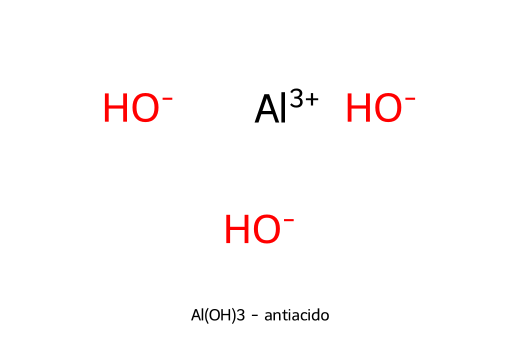

In [5]:
# @title Estrutura 2D com os risquinhos das ligações
from rdkit import Chem
from rdkit.Chem import rdDepictor
from rdkit.Chem.Draw import rdMolDraw2D
from IPython.display import SVG

rdDepictor.SetPreferCoordGen(True)   # layout 2D no estilo de livro didático

def estrutura_2d(smiles, legenda="", largura=520, altura=360, mostrar_h=False):
    """SMILES -> SVG. Um traço = simples, dois = dupla, três = tripla.

    A legenda fica em ASCII porque o desenho do RDKit corrompe acento e
    subscrito (para título bonito, use matplotlib).
    """
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        raise ValueError(f"SMILES inválido: {smiles!r}")
    if mostrar_h:
        mol = Chem.AddHs(mol)
    rdDepictor.Compute2DCoords(mol)

    desenho = rdMolDraw2D.MolDraw2DSVG(largura, altura)
    desenho.drawOptions().bondLineWidth = 2.2
    desenho.drawOptions().padding = 0.10
    desenho.DrawMolecule(mol, legend=legenda)
    desenho.FinishDrawing()
    return SVG(desenho.GetDrawingText())

estrutura_2d("[Mg+2].[OH-].[OH-]", legenda="Mg(OH)2 - leite de magnesia")
estrutura_2d("[Al+3].[OH-].[OH-].[OH-]", legenda="Al(OH)3 - antiacido")

### 4.4 Bases na limpeza e na cozinha

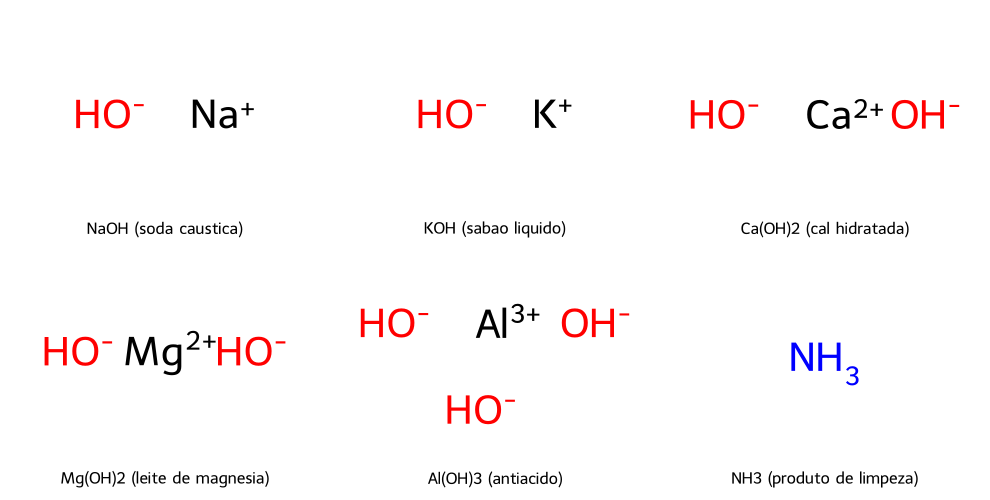

In [6]:
# @title Hidróxidos do cotidiano
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import SVG

produtos = [
    ("NaOH (soda caustica)", "[Na+].[OH-]"),
    ("KOH (sabao liquido)", "[K+].[OH-]"),
    ("Ca(OH)2 (cal hidratada)", "[Ca+2].[OH-].[OH-]"),
    ("Mg(OH)2 (leite de magnesia)", "[Mg+2].[OH-].[OH-]"),
    ("Al(OH)3 (antiacido)", "[Al+3].[OH-].[OH-].[OH-]"),
    ("NH3 (produto de limpeza)", "N"),
]
imagem = Draw.MolsToGridImage([Chem.MolFromSmiles(s) for _, s in produtos],
                              molsPerRow=3, subImgSize=(330, 250),
                              legends=[nome for nome, _ in produtos], useSVG=True)
imagem if hasattr(imagem, "data") else SVG(imagem)

### 4.5 pH das bases de casa

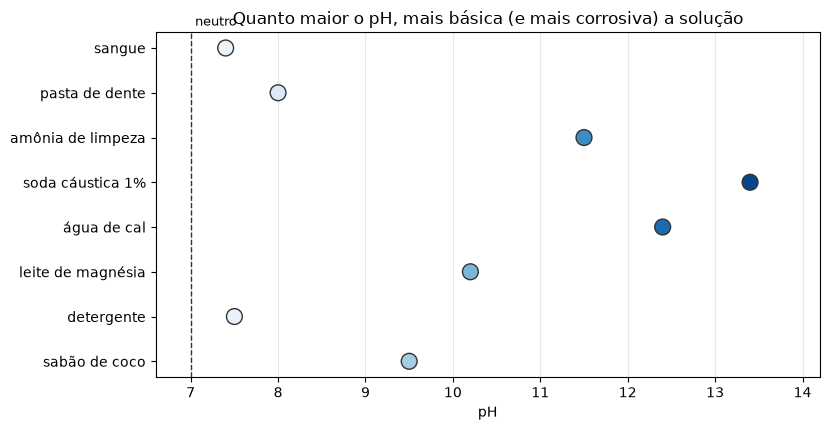

In [7]:
# @title pH de produtos básicos
import matplotlib.pyplot as plt

itens = [
    ("sabão de coco", 9.5), ("detergente", 7.5), ("leite de magnésia", 10.2),
    ("água de cal", 12.4), ("soda cáustica 1%", 13.4),
    ("amônia de limpeza", 11.5), ("pasta de dente", 8.0), ("sangue", 7.4),
]
nomes = [nome for nome, _ in itens]
valores = [valor for _, valor in itens]

plt.figure(figsize=(8.4, 4.4))
cores = plt.cm.Blues([(v - 7) / 7 for v in valores])
plt.scatter(valores, range(len(itens)), s=130, c=cores, edgecolor="#333", zorder=3)
plt.yticks(range(len(itens)), nomes)
plt.axvline(7, color="#333", linestyle="--", linewidth=1)
plt.text(7.05, 7.5, "neutro", fontsize=9)
plt.xlim(6.6, 14.2)
plt.xlabel("pH")
plt.title("Quanto maior o pH, mais básica (e mais corrosiva) a solução")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

### 4.6 Neutralizando o ácido do estômago

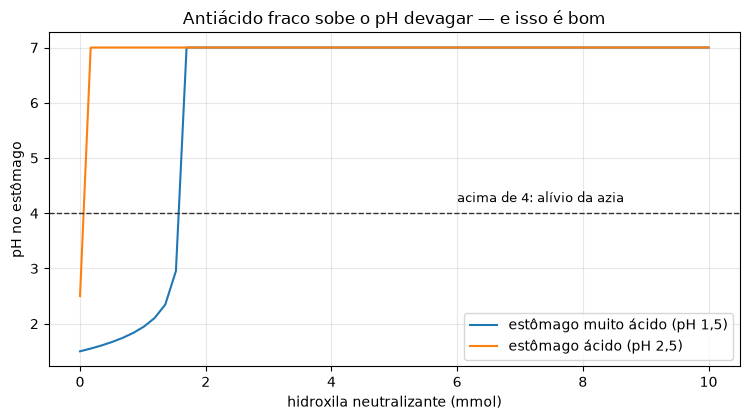

In [8]:
# @title Simulação: pH gástrico com antiácido
import numpy as np

def ph_apos_antiacido(ph_inicial, volume_estomago, moles_neutralizados):
    """Aproximação: cada mol de OH- consome 1 mol de H+ do estômago."""
    h_inicial = 10 ** (-ph_inicial)
    n_h = h_inicial * volume_estomago
    n_restante = max(n_h - moles_neutralizados, 0.0)
    if n_restante <= 0:
        return 7.0        # neutralizou tudo (na prática o corpo reage e reacidifica)
    return -np.log10(n_restante / volume_estomago)

V_ESTOMAGO = 0.050          # L (~50 mL de suco gástrico)
doses = np.linspace(0, 0.010, 60)   # mol de OH- liberado (0 a 10 mmol)

plt.figure(figsize=(7.6, 4.3))
for ph0, rotulo in [(1.5, "estômago muito ácido (pH 1,5)"),
                    (2.5, "estômago ácido (pH 2,5)")]:
    plt.plot(doses * 1000, [ph_apos_antiacido(ph0, V_ESTOMAGO, d) for d in doses], label=rotulo)
plt.axhline(4, color="#333", linestyle="--", linewidth=1)
plt.text(6, 4.2, "acima de 4: alívio da azia", fontsize=9)
plt.xlabel("hidroxila neutralizante (mmol)")
plt.ylabel("pH no estômago")
plt.title("Antiácido fraco sobe o pH devagar — e isso é bom")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Como interpretar o resultado

- 50% m/m com densidade 1,52 dá **19 mol/L**: soda cáustica comercial é muito mais concentrada do que qualquer solução de laboratório. Sempre dilua em água, nunca o contrário, e com EPI.
- Antiácidos de hidróxidos metálicos são **pouco solúveis** de propósito: a liberação lenta evita o efeito rebote (produção excessiva de ácido depois).
- A saponificação é o que torna a soda perigosa para a pele: ela transforma a gordura da pele em sabão, literalmente.
- Cal hidratada ($\mathrm{Ca(OH)_2}$) é base forte, mas pouco solúvel: a "água de cal" tem pH alto com concentração baixíssima.

## 6. Exercício de fixação

Um frasco de limpeza traz "hidróxido de sódio 2,0% m/m, densidade 1,02 g/mL". Qual é a concentração em mol/L e o pH aproximado?

In [9]:
# @title Exercício
teor_ex, d_ex = 0.020, 1.02
c_ex = 10 * d_ex * teor_ex / M_NAOH      # fórmula prática para % m/m -> mol/L
print(f"concentração = {c_ex:.3f} mol/L")
print(f"pOH = {-__import__('math').log10(c_ex):.2f}")
print(f"pH  = {14 + __import__('math').log10(c_ex):.2f}")

concentração = 0.005 mol/L
pOH = 2.29
pH  = 11.71


## 7. Resumo

- Bases do cotidiano: soda (NaOH), potassa (KOH), cal (Ca(OH)₂), leite de magnésia (Mg(OH)₂), antiácidos (Al(OH)₃), amônia.
- $\%m/m \rightarrow \mathrm{mol/L}$: $c = 10\,d\,\text{teor}/M$.
- Saponificação: base forte + gordura → sabão + glicerol.
- Antiácidos funcionam por serem bases fracas/pouco solúveis, liberando $\mathrm{OH^-}$ devagar.
- Bases fortes exigem EPI: corroem pele e olhos.

## Referências

- ATKINS, P.; JONES, L. *Princípios de Química*. Bookman.
- ANVISA. Bulas e rótulos de medicamentos antiácidos.
- FELTRE, R. *Química Geral*. Moderna.